## Script to process multiple years to find the winter like and summer like days from NASA NEX-GDP-CMIP6 models

In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft

from cartopy import crs as ccrs, feature as cfeature
import netCDF4
from netCDF4 import Dataset
from datetime import datetime as dt

import os
import warnings
warnings.filterwarnings('ignore')



In [2]:
###################
# helper functions
###################
def WinterSummerDays(temp_data, temp_data_next, winter_threshold, summer_threshold, show_plot):
    '''

    Function that uses the input 25th and 75th percentile temperature in K to identify summer-like and winter-like days and Tmin day from a time series of temperatures.
    Input data should already be set to 365 days.

    Args:
        temp_data: xarray of temperature data for a single grid cell for the year of interest
        temp_data_next: xarray of temperature data for a single grid cell for the following year (for NH winters, SH summers)
        winter_threshold: xarray for the 25th percentile threshold to use
        summer_threshold: xarray for the 75th percentile threshold to use
        show_plots: boolean for whether to plot the summer and winter time series with the labeled WLD and SLD, max and min
        
    Returns:
        first WLD: first DOY that daily mean t2m is below winter threshold (25th percentile)
        last WLD: last DOY that daily mean t2m is below winter threshold (25th percentile)
        first SLD: first DOY that daily mean t2m is above summer threshold (75th percentile)
        last SLD: last DOY that daily mean t2m is above summer threshold (75th percentile)
        winterlike days: number of days in the 12 month period that had a mean T2m <= the winter threshold
        summerlike days: number of days in the 12 month period that had a mean T2m >= the summer threshold
        
    Example:
        first_wld, last_wld, first_sld, last_sld, winterlike_days, summerlike_days = WinterSummerDays(temps, temps_next, winter_threshold, summer_threshold, True)

    '''

    # default values
    first_wld = 0 
    last_wld = 0
    first_sld = 0 
    last_sld = 0
    winter_like_days = 0
    summer_like_days = 0

    # split method based on NH or SH
    # WLD should be counted and indexed over the cycle with winter at the center to see trends over time
    # otherwise the first WLD will nearly always be day 1 of the year in the NH 
    # similarly for SLD in the SH we want the summer months of DJF to be in the center of the cycle

    # extract DOY and T2m values for those days from just the current year
    x1_cur = temp_data.time.dt.dayofyear.values
    y1_cur = temp_data.values

    # same but for current plus next for SH summer and NH winter
    ds_two = xr.concat([temp_data, temp_data_next], dim="time")

    # get the current year for slicing
    input_year = temp_data.time.dt.year.values[0]

    # select July 1 - June 30 across the two years to do fit
    startdate = str(input_year)+'-07-01' # 182nd day of a normal year
    enddate = str(input_year+1)+'-06-30'
    offset_yr = ds_two.sel(time=slice(startdate,enddate))
    
    # DOY (relative to July 1) and T2m values for those days
    x1_off = np.arange(1,len(offset_yr.time)+1) 
    y1_off = offset_yr.values

    ######
    # Southern Hemisphere 
    ######
    if temp_data.lat.values < 0:
        ########
        # Winter uses current year only

        # count of winter-like days in the year (any time during the year)
        # and the first/last occurence where the winter months (JJA) are centered in the cycle
        winter_like_days = np.where(y1_cur <= winter_threshold.values)[0].size

        # handle the case where NO days are below the threshold for winter
        if winter_like_days > 0:
            first_wld = np.where(y1_cur <= winter_threshold.values)[0][0] + 1 # +1 because zero-indexing in python
            last_wld = np.where(y1_cur <= winter_threshold.values)[0][-1] + 1

        ########
        # Summer uses current year and next year

        # count of summer-like days in the year (any time during the "year)"
        # and the first/last occurence where the summer months (DJF) are centered in the cycle
        summer_like_days = np.where(y1_off >= summer_threshold.values)[0].size

        # handle the case where no days are above summer threshold (seems unlikely but just in case)
        if summer_like_days > 0:
            first_sld = np.where(y1_off >= summer_threshold.values)[0][0] + 1 # +1 because zero-indexing in python
            last_sld = np.where(y1_off >= summer_threshold.values)[0][-1] + 1

        if show_plot:
            fs = 8
            cell_lat = temp_data.lat.values
            cell_lon = temp_data.lon.values
            yr = temp_data.time.dt.year.values[0]
            
            fig = plt.figure(figsize=(16,5), layout='constrained')
            # SH winter
            ax1 = fig.add_subplot(1,2,1)
            ax1.plot(x1_cur,y1_cur, label='daily mean T2m')
            ax1.axhline(winter_threshold.values[0], color="black", linewidth=0.8, linestyle="dashed")
            ax1.annotate('first WLD', xy=(first_wld,np.min(y1_cur)), fontsize=fs, 
                         arrowprops = dict(facecolor ='green', shrink = 0.05))
            ax1.annotate('last WLD', xy=(last_wld,np.min(y1_cur)), fontsize=fs, 
                         arrowprops = dict(facecolor ='green', shrink = 0.05))
            ax1.annotate('25th percentile = '+str(np.round(winter_threshold.values[0],1))+'K', xy=(0,winter_threshold.values[0]+1), fontsize=fs+2)
            ax1.set_xlabel('DOY (' + str(yr) + ')')
            ax1.set_ylabel('Mean Daily Temp (K)')
            ax1.set_title(str(yr) + " Winter for Lat,Lon = [" +str(cell_lat)+","+str(cell_lon)+ "] Baseline Years = (1961-1990)")

            # SH Summer
            ax2 = fig.add_subplot(1,2,2)
            ax2.plot(x1_off,y1_off, label='daily mean T2m')
            ax2.axhline(summer_threshold.values[0], color="black", linewidth=0.8, linestyle="dashed")
            ax2.annotate('first SLD', xy=(first_sld,np.min(y1_off)), fontsize=fs, 
                         arrowprops = dict(facecolor ='red', shrink = 0.05))
            ax2.annotate('last SLD', xy=(last_sld,np.min(y1_off)), fontsize=fs, 
                         arrowprops = dict(facecolor ='red', shrink = 0.05))
            ax2.annotate('75th percentile = '+str(np.round(summer_threshold.values[0],1))+'K', xy=(0,summer_threshold.values[0]+1), fontsize=fs+2)
            ax2.set_xlabel('DOY (' + str(yr) + ') relative to July 1')
            ax2.set_ylabel('Mean Daily Temp (K)')
            ax2.set_title(str(yr) + " Summer for Lat,Lon = [" +str(cell_lat)+","+str(cell_lon)+ "] Baseline Years = (1961-1990)")
            plt.show()
    
    ######
    # Northern Hemisphere 
    # winter uses current year and following year
    else: 

        # Winter
        # count of winter-like days in the year (any time during the year)
        # and the first/last occurence where the winter months (DJF) are centered in the cycle
        winter_like_days = np.where(y1_off <= winter_threshold.values)[0].size

        # handle the case where NO days are below the threshold for winter
        if winter_like_days > 0:
            first_wld = np.where(y1_off <= winter_threshold.values)[0][0] + 1 # +1 because zero-indexing in python
            last_wld = np.where(y1_off <= winter_threshold.values)[0][-1] + 1

        # Summer       
        # count of summer-like days in the year (any time during the year)
        # and the first/last occurence where the summer months (JJA) are centered in the cycle
        summer_like_days = np.where(y1_cur >= summer_threshold.values)[0].size

        # handle the case where no days are above summer threshold (seems unlikely but just in case)
        if summer_like_days > 0:
            first_sld = np.where(y1_cur >= summer_threshold.values)[0][0] + 1 # +1 because zero-indexing in python
            last_sld = np.where(y1_cur >= summer_threshold.values)[0][-1] + 1
                
        if show_plot:
            fs = 8
            cell_lat = temp_data.lat.values
            cell_lon = temp_data.lon.values
            yr = temp_data.time.dt.year.values[0]
            
            fig = plt.figure(figsize=(16,5), layout='constrained')
            # NH Winter
            ax1 = fig.add_subplot(1,2,1)
            ax1.plot(x1_off,y1_off, label='daily mean T2m')
            ax1.axhline(winter_threshold.values[0], color="black", linewidth=0.8, linestyle="dashed")
            ax1.annotate('first WLD', xy=(first_wld,np.min(y1_off)), fontsize=fs, 
                         arrowprops = dict(facecolor ='green', shrink = 0.05))
            ax1.annotate('last WLD', xy=(last_wld,np.min(y1_off)), fontsize=fs, 
                         arrowprops = dict(facecolor ='green', shrink = 0.05))
            ax1.annotate('25th percentile = '+str(np.round(winter_threshold.values[0],1))+'K', xy=(0,winter_threshold.values[0]+1), fontsize=fs+2)
            ax1.set_xlabel('DOY (' + str(yr) + ') relative to July 1')
            ax1.set_ylabel('Mean Daily Temp (K)')
            ax1.set_title(str(yr) + " Winter for Lat,Lon = [" +str(cell_lat)+","+str(cell_lon)+ "] Baseline Years = (1961-1990)")

            # NH Summer
            ax2 = fig.add_subplot(1,2,2)
            ax2.plot(x1_cur,y1_cur, label='daily mean T2m')
            ax2.axhline(summer_threshold.values[0], color="black", linewidth=0.8, linestyle="dashed")
            ax2.annotate('first SLD', xy=(first_sld,np.min(y1_cur)), fontsize=fs, 
                         arrowprops = dict(facecolor ='red', shrink = 0.05))
            ax2.annotate('last SLD', xy=(last_sld,np.min(y1_cur)), fontsize=fs, 
                         arrowprops = dict(facecolor ='red', shrink = 0.05))
            ax2.annotate('75th percentile = '+str(np.round(summer_threshold.values[0],1))+'K', xy=(0,summer_threshold.values[0]+1), fontsize=fs+2)
            ax2.set_xlabel('DOY (' + str(yr) + ')')
            ax2.set_ylabel('Mean Daily Temp (K)')
            ax2.set_title(str(yr) + " Summer for Lat,Lon = [" +str(cell_lat)+","+str(cell_lon)+ "] Baseline Years = (1961-1990)")
            plt.show()       
    
    # return
    return int(first_wld), int(last_wld), int(first_sld), int(last_sld), int(winter_like_days), int(summer_like_days)
    




In [3]:
# a function that takes in a dataset of global t2m values and if it is a leap year averages
# the temps on Feb 28 & Feb 29, then drops Feb 29 to ensure the year has 365 days
def HandleLeapYears(input_ds):
    '''

    Function that takes the mean of Feb 28 & Feb 29 (if it exists) and returns an xarray Dataset that has 365 days
    where Feb 28 will now have a tas value that is the mean of Feb 28 & Feb 29

    Args:
        input_ds: the data set containing a single year of data that may need adjusting for leap year
        
    Returns:
        output_ds
        
    Example:
        no_leap_ds = HandleLeapYears(input_ds)

    '''
    

    # check if a leap year
    if(input_ds.time.dt.is_leap_year[0].values):
        
        # make deep copy
        output_ds = input_ds.copy(deep=True)
        
        # get mean of Feb 28 (time index 58) & Feb 29 (time index 59) for each grid cell and overwrite Feb 28 with it
        mean_dat = output_ds.tas[58:60].mean(dim='time', skipna=True, keep_attrs=True)
        output_ds.tas[58] = mean_dat
        
        # drop Feb 29
        output_ds = output_ds.convert_calendar('noleap', use_cftime=None)

        # ensure time is datetime64
        output_ds["time"] = output_ds.time.dt.strftime('%Y-%m-%d')
        output_ds['time'] = pd.to_datetime(output_ds['time'])

        # return the new dataset 
        return output_ds
    else:
        return input_ds
    

## Test one model to verify algorithm

In [4]:
#os.chdir('../../../../Data/CMIP6/NEX-GDDP-CMIP6/MIROC6/regridded/')
!ls -al '../../../../Data/CMIP6/NEX-GDDP-CMIP6/MIROC6/regridded/'

total 74672504
drwxr-xr-x@ 320 tedscott  staff      10240 Nov 25 11:14 .
drwxr-xr-x@   5 tedscott  staff        160 Nov  4 11:52 ..
-rw-r--r--@   1 tedscott  staff       6148 Nov 25 15:20 .DS_Store
-rw-r--r--@   1 tedscott  staff    4182376 Nov  5 07:52 computed_1961-1990-full_25th.nc
-rw-r--r--@   1 tedscott  staff    4182376 Nov  5 07:50 computed_1961-1990-full_75th.nc
drwxr-xr-x@ 106 tedscott  staff       3392 Nov 25 08:25 Seasons
drwxr-xr-x@ 226 tedscott  staff       7232 Nov  8 19:03 Summers
-rw-r--r--@   1 tedscott  staff  249807334 Nov  4 07:37 tas_MIROC6_historical_1961.nc
-rw-r--r--@   1 tedscott  staff  255015385 Nov  4 07:49 tas_MIROC6_historical_1962.nc
-rw-r--r--@   1 tedscott  staff  251436714 Nov  4 08:01 tas_MIROC6_historical_1963.nc
-rw-r--r--@   1 tedscott  staff  258123473 Nov  4 08:13 tas_MIROC6_historical_1964.nc
-rw-r--r--@   1 tedscott  staff  259819321 Nov  4 08:25 tas_MIROC6_historical_1965.nc
-rw-r--r--@   1 tedscott  staff  262205955 Nov  4 11:33 tas_MIROC6_h

In [12]:
os.chdir("../../../../../Codes/HeatWaves/HeatWaves/SeasonsNEX-GDDP-CMIP6/")
!ls -al

total 31512
drwxr-xr-x@ 15 tedscott  staff      480 Nov 24 15:08 .
drwx------@ 99 tedscott  staff     3168 Nov 24 15:10 ..
drwxr-xr-x@ 14 tedscott  staff      448 Nov 18 09:22 .ipynb_checkpoints
-rw-r--r--@  1 tedscott  staff   267416 Nov 24 07:23 AnalyzeSeasonsGWLs.ipynb
-rw-r--r--@  1 tedscott  staff  3598309 Nov 19 12:53 AnalyzeSeasonsNEX-GDDP-CMIP6.ipynb
-rw-r--r--@  1 tedscott  staff   283265 Nov 24 07:23 GatherWLDSLD_NEX-GDDP-CMIP6.ipynb
-rw-r--r--@  1 tedscott  staff   115920 Nov 18 14:46 ProcessNEX-GDDP-CMIP6_SeasonLengths.ipynb
-rw-r--r--@  1 tedscott  staff   115913 Nov 11 14:40 ProcessNEX-GDDP-CMIP6_SeasonLengthsParallel1.ipynb
-rw-r--r--@  1 tedscott  staff   109545 Nov 11 20:25 ProcessNEX-GDDP-CMIP6_SeasonLengthsParallel2.ipynb
-rw-r--r--@  1 tedscott  staff   109524 Nov 13 07:18 ProcessNEX-GDDP-CMIP6_SeasonLengthsParallel3.ipynb
-rw-r--r--@  1 tedscott  staff  5417315 Nov 24 07:23 SeasonLengthsMapsTrendsNEX-GDDP-CMIP6.ipynb
-rw-r--r--@  1 tedscott  staff  4792738 Oct 20 1

In [18]:
%%time

input_year = 2027

md = 'MIROC6'

# summer thresh
file_path1 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/computed_1961-1990-full_75th.nc'
c_75 = xr.open_dataarray(file_path1)

# winter thresh
file_path2 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/computed_1961-1990-full_25th.nc'
c_25 = xr.open_dataarray(file_path2)

c_25, c_75





CPU times: user 7.79 ms, sys: 18.4 ms, total: 26.2 ms
Wall time: 33.5 ms


(<xarray.DataArray 'tas' (model: 1, lat: 721, lon: 1440)> Size: 4MB
 [1038240 values with dtype=float32]
 Coordinates:
   * model     (model) <U6 24B 'MIROC6'
   * lat       (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
   * lon       (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
     quantile  float64 8B ...
 Attributes:
     long_name:  25th percentile 2m Temperature for the data across available ...
     units:      K,
 <xarray.DataArray 'tas' (model: 1, lat: 721, lon: 1440)> Size: 4MB
 [1038240 values with dtype=float32]
 Coordinates:
   * model     (model) <U6 24B 'MIROC6'
   * lat       (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
   * lon       (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
     quantile  float64 8B ...
 Attributes:
     long_name:  75th percentile 2m Temperature for the data across available ...
     units:      K)

In [19]:
!cdo info ../../../../Data/CMIP6/NEX-GDDP-CMIP6/MIROC6/regridded/tas_MIROC6_ssp245_2027.nc

    -1 :       Date     Time   Level Gridsize    Miss :     Minimum        Mean     Maximum : Parameter ID
     1 : 2027-01-01 12:00:00       0  1038240  785885 :      224.42      273.49      310.11 : -1            
     2 : 2027-01-02 12:00:00       0  1038240  785885 :      222.37      273.71      311.23 : -1            
     3 : 2027-01-03 12:00:00       0  1038240  785885 :      220.89      273.58      312.28 : -1            
     4 : 2027-01-04 12:00:00       0  1038240  785885 :      218.68      273.41      311.92 : -1            
     5 : 2027-01-05 12:00:00       0  1038240  785885 :      216.62      273.23      311.99 : -1            
     6 : 2027-01-06 12:00:00       0  1038240  785885 :      215.92      272.89      311.15 : -1            
     7 : 2027-01-07 12:00:00       0  1038240  785885 :      216.60      272.73      310.90 : -1            
     8 : 2027-01-08 12:00:00       0  1038240  785885 :      216.59      272.70      311.63 : -1            
     9 : 2027-01-09 1

In [20]:
%%time


file_path1 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/tas_'+md+'_ssp245_'+str(input_year)+'.nc'
dsnow = xr.open_mfdataset(file_path1)
dsnow = HandleLeapYears(dsnow)
dsnow.load()

file_path2 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/tas_'+md+'_ssp245_'+str(input_year+1)+'.nc'
dsnext = xr.open_mfdataset(file_path2)
dsnext = HandleLeapYears(dsnext)
dsnext.load()

<xarray.Dataset> Size: 2GB
Dimensions:  (time: 365, lat: 721, lon: 1440)
Coordinates:
  * time     (time) datetime64[us] 3kB 2028-01-01 2028-01-02 ... 2028-12-31
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    tas      (time, lat, lon) float32 2GB nan nan nan nan ... nan nan nan nan
Attributes: (12/24)
    CDI:                   Climate Data Interface version 2.5.0 (https://mpim...
    Conventions:           CF-1.7
    source:                BCSD
    institution:           NASA Earth Exchange, NASA Ames Research Center, Mo...
    activity:              NEX-GDDP-CMIP6
    frequency:             day
    ...                    ...
    contact:               Dr. Bridget Thrasher: bridget@climateanalyticsgrou...
    creation_date:         Sun Nov 17 02:58:08 PST 2024
    disclaimer:            These data are considered provisional and subject ...
    tracking_id:           ce967377-3a9d-46af-a476-8c5a75af7e7c
    history:               Thu Nov 05 11:47:22 2026: cdo -sellonlatbox,-180,1...
    CDO:                   Climate Data Operators version 2.5.0 (https://mpim...

In [21]:
#test for Vancouver
input_lat = 49.246
input_lon = -123.116

summer_thresh = c_75.sel(lat=input_lat, lon=input_lon, method="nearest")
winter_thresh = c_25.sel(lat=input_lat, lon=input_lon, method="nearest")
summer_thresh.values, winter_thresh.values

(array([287.25497], dtype=float32), array([279.13614], dtype=float32))

In [22]:

curr = dsnow.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
curr, nxt

(<xarray.DataArray 'tas' (time: 365)> Size: 1kB
 array([282.54202, 279.4582 , 278.03705, 276.9148 , 272.4533 , 273.95834,
        269.4713 , 267.23352, 271.23172, 274.6848 , 277.6233 , 276.53336,
        272.83545, 272.86548, 273.08237, 277.43408, 280.4582 , 281.27945,
        280.0329 , 278.4314 , 280.3354 , 281.87805, 280.8874 , 280.00043,
        278.94092, 282.83472, 286.2074 , 286.28662, 287.1724 , 286.75232,
        281.77847, 277.50522, 279.13123, 278.74182, 279.95593, 281.82413,
        282.32248, 284.28302, 283.53146, 285.275  , 285.05768, 284.99353,
        286.3141 , 282.95755, 282.28137, 283.88623, 282.7559 , 282.63507,
        286.792  , 286.83798, 282.38208, 282.17322, 282.4875 , 280.506  ,
        280.83142, 279.40927, 278.04684, 278.21014, 278.2552 , 280.33807,
        281.37042, 281.7335 , 281.57037, 283.18103, 282.72052, 281.3125 ,
        282.46017, 284.07495, 284.72906, 285.58994, 285.0856 , 284.26248,
        283.1257 , 284.55786, 283.92624, 285.8792 , 283.92975, 2

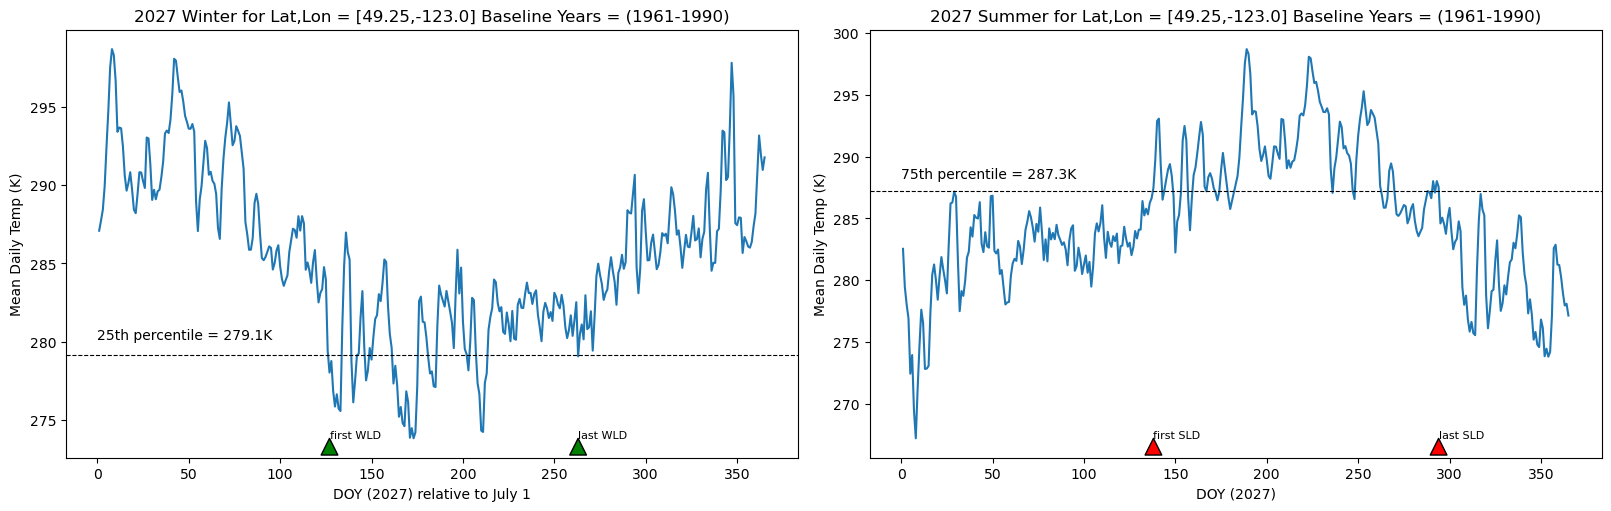

(127, 263, 138, 294, 41, 112)

In [23]:
firstwld, lastwld, firstsld, lastsld, winterlikedays, summerlikedays = WinterSummerDays(curr, nxt, winter_thresh, summer_thresh, True)
firstwld, lastwld, firstsld, lastsld, winterlikedays, summerlikedays

In [24]:
# Sydney
input_lat = -33 - 52/60 - 4/3600
input_lon = 151.25

summer_thresh = c_75.sel(lat=input_lat, lon=input_lon, method="nearest")
winter_thresh = c_25.sel(lat=input_lat, lon=input_lon, method="nearest")
summer_thresh.values, winter_thresh.values

(array([294.05774], dtype=float32), array([287.13275], dtype=float32))

In [25]:
curr = dsnow.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
curr, nxt

(<xarray.DataArray 'tas' (time: 365)> Size: 1kB
 array([299.6592 , 301.45737, 300.76917, 303.80154, 297.06143, 297.23108,
        295.38303, 298.0462 , 300.0722 , 297.6596 , 298.48367, 298.49457,
        298.11865, 298.12674, 298.18353, 298.37628, 298.68976, 299.10986,
        296.1995 , 295.53372, 298.9966 , 300.98175, 301.49603, 301.51727,
        301.16986, 298.327  , 296.7901 , 298.0302 , 297.2855 , 296.07916,
        298.3603 , 300.1918 , 297.65146, 295.20447, 295.59845, 297.32037,
        294.69815, 295.6253 , 297.9947 , 297.0683 , 298.5013 , 295.81876,
        294.3871 , 296.52402, 298.74768, 299.0335 , 297.82428, 299.0384 ,
        299.7222 , 297.8382 , 295.3938 , 296.27533, 295.5297 , 295.35562,
        293.10153, 294.61008, 294.7813 , 294.23846, 295.97296, 296.98563,
        298.2441 , 298.60974, 296.9324 , 296.56564, 296.5297 , 295.6054 ,
        295.2669 , 296.48557, 296.82565, 297.4543 , 298.34607, 297.50882,
        295.90796, 297.6845 , 292.87598, 291.4095 , 292.1728 , 2

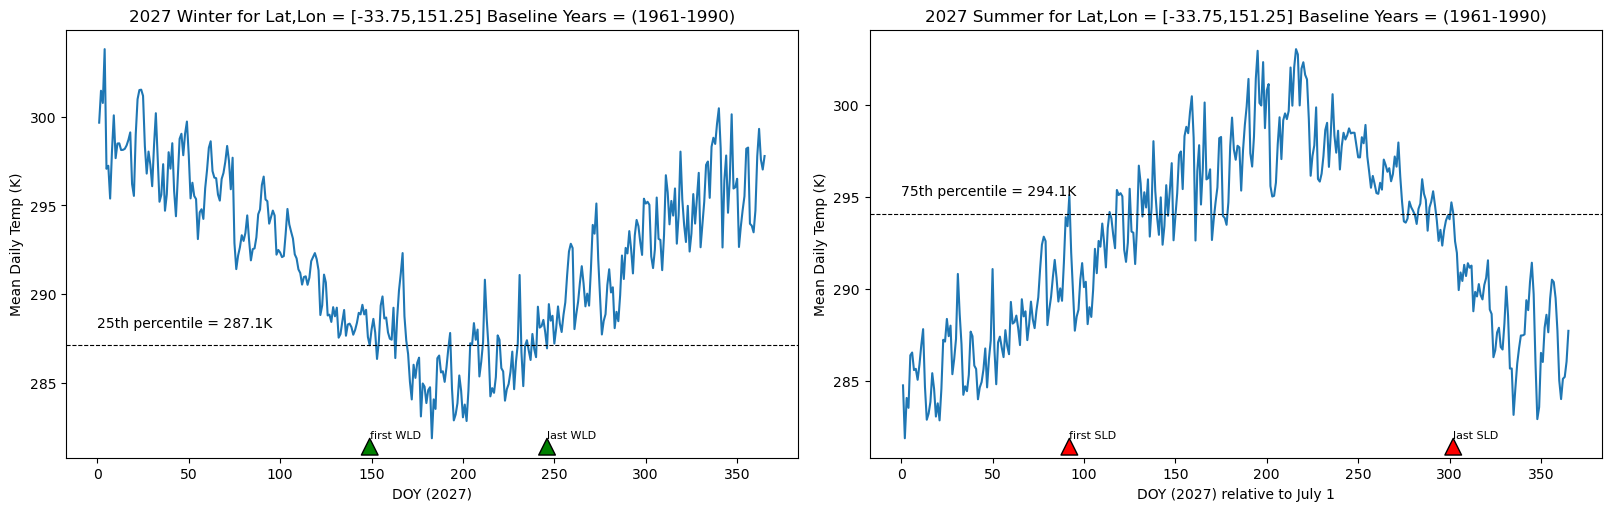

(149, 246, 92, 302, 60, 151)

In [26]:
firstwld, lastwld, firstsld, lastsld, winterlikedays, summerlikedays = WinterSummerDays(curr, nxt, winter_thresh, summer_thresh, True)
firstwld, lastwld, firstsld, lastsld, winterlikedays, summerlikedays

#### Looks to be working for Vancouver and Sydney

## Process all years and experiments for set of models

In [ ]:
%%time

# 18 min per year
# roughly 2d 18h per model!

# comment out as needed
models = [#'ACCESS-ESM1-5',
    #'BCC-CSM2-MR',
    #'CMCC-ESM2',
    #'FGOALS-g3',
    #'GFDL-ESM4',
    #'GISS-E2-1-G',
    #'MIROC-ES2L',
    'MIROC6',
    #'MPI-ESM1-2-HR',
    #'MRI-ESM2-0',
    #'NorESM2-LM'
]

# run through the list of models
for md in models:

    start = dt.now()

    # summer thresh
    file_path1 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/computed_1961-1990-full_75th.nc'
    c_75 = xr.open_dataarray(file_path1)

    # winter thresh
    file_path2 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/computed_1961-1990-full_25th.nc'
    c_25 = xr.open_dataarray(file_path2)

    # grid parameters for looping
    num_lat = c_75.lat.shape[0]
    num_lon = c_75.lon.shape[0]
    loop_lats = c_75.lat.values[:num_lat]
    loop_lons = c_75.lon.values[:num_lon]

    # ######
    # # Historical period
    # process_yrs = np.arange(1961, 2015,1) 
    
    # # loop thru the years in the defined array above
    # for input_year in process_yrs:
    
    #     start_yr = dt.now()

    #     # don't need to load in current year if we've already loaded it
    #     if input_year == 1961:
    #         # read in current year and next year
    #         # load into memory to speed up the processing and handle leap years to be 365 days
    #         file_path1 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/tas_'+md+'_historical_'+str(input_year)+'.nc'
    #         dsnow = xr.open_mfdataset(file_path1)
    #         dsnow = HandleLeapYears(dsnow)
    #         dsnow.load()
    #     else:
    #         dsnow = dsnext

    #     # Note: to process 2014 we need 2015 for SH summer so using ssp245 2015 for that one added year
    #     if input_year < 2014:
    #         file_path2 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/tas_'+md+'_historical_'+str(input_year+1)+'.nc'
    #     else:
    #         file_path2 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/tas_'+md+'_ssp245_2015.nc'
    #     dsnext = xr.open_mfdataset(file_path2)
    #     dsnext = HandleLeapYears(dsnext)
    #     dsnext.load()
    
    #     # empty data arrays for stats
    #     first_wld = xr.DataArray(np.zeros((num_lat,num_lon)), 
    #                                 coords=[loop_lats, loop_lons], 
    #                                 dims=['lat','lon'])
    #     last_wld = xr.DataArray(np.zeros((num_lat,num_lon)), 
    #                                coords=[loop_lats, loop_lons], 
    #                                dims=['lat','lon'])
    #     first_sld = xr.DataArray(np.zeros((num_lat,num_lon)), 
    #                              coords=[loop_lats, loop_lons], 
    #                              dims=['lat','lon'])
    #     last_sld = xr.DataArray(np.zeros((num_lat,num_lon)), 
    #                              coords=[loop_lats, loop_lons], 
    #                              dims=['lat','lon'])
    #     winterlike_days = xr.DataArray(np.zeros((num_lat,num_lon)), 
    #                              coords=[loop_lats, loop_lons], 
    #                              dims=['lat','lon'])
    #     summerlike_days = xr.DataArray(np.zeros((num_lat,num_lon)), 
    #                              coords=[loop_lats, loop_lons], 
    #                              dims=['lat','lon'])
        
    #     # add attributes
    #     first_wld.attrs["long_name"] = "First day with mean T2m at or below winter threshold for the year (DOY in [1,365])"
    #     first_wld.attrs["units"] = "Day of year"
        
    #     last_wld.attrs["long_name"] = "Last day with mean T2m at or below winter threshold for the year (DOY in [1,365])"
    #     first_wld.attrs["units"] = "Day of year"
        
    #     first_sld.attrs["long_name"] = "First day with mean T2m at or above summer threshold for the year (DOY in [1,365])"
    #     first_sld.attrs["units"] = "Day of year"
        
    #     last_sld.attrs["long_name"] = "Last day with mean T2m at or above summer threshold for the year (DOY in [1,365])"
    #     first_sld.attrs["units"] = "Day of year"
        
    #     winterlike_days.attrs["long_name"] = "Number of days during the year where winter is centered with mean T2m at or below threshold"
    #     winterlike_days.attrs["units"] = "Days"
        
    #     summerlike_days.attrs["long_name"] = "Number of days during the year where summer is centered with mean T2m at or above threshold"
    #     summerlike_days.attrs["units"] = "Days"

    #     # loop through all of the lat,lon of interest
    #     for input_lat in loop_lats:
    #         for input_lon in loop_lons:
    #             # get thresholds from c_25 and c_75
    #             winter_thresh = c_25.sel(lat=input_lat,lon=input_lon)
    #             summer_thresh = c_75.sel(lat=input_lat,lon=input_lon)
    
    #             # if winter_thresh is nan this cell is not on land and/or outside lat range of data so skip it and set all metrics to nan
    #             if(np.isnan(winter_thresh[0])):
    #                 firstwld, lastwld, firstsld, lastsld, winterlikedays, summerlikedays = np.nan, np.nan, np.nan, np.nan, np.nan, np.nan 
                    
    #             else:
    #                 # all the temps for that grid cell over time for this year and next (for SH)
    #                 curr = dsnow.tas.sel(lat=input_lat,lon=input_lon) 
    #                 nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon)

    #                 # build winter stats for the grid cell and produce the plot if desired (currently False)
    #                 firstwld, lastwld, firstsld, lastsld, winterlikedays, summerlikedays = WinterSummerDays(curr, nxt, winter_thresh, summer_thresh, False)

    #             # xarray requires strange indexing in order to replace values by coordinate
    #             first_wld.loc[input_lat, input_lon] = firstwld
    #             last_wld.loc[input_lat, input_lon] = lastwld
    #             first_sld.loc[input_lat, input_lon] = firstsld
    #             last_sld.loc[input_lat, input_lon] = lastsld
    #             winterlike_days.loc[input_lat, input_lon] = winterlikedays
    #             summerlike_days.loc[input_lat, input_lon] = summerlikedays

    #     # save it out
    #     sum_ds = xr.Dataset(data_vars={'FirstWLD':first_wld,
    #                            'LastWLD':last_wld,
    #                                'FirstSLD':first_sld,
    #                            'LastSLD':last_sld,
    #                                'WinterlikeDays':winterlike_days,
    #                                'SummerlikeDays':summerlike_days})    

    #     output_path = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/Seasons/'+str(input_year)+'_'+md+'_historical_summer_winter_days.nc'
    #     sum_ds.to_netcdf(output_path)

    #     end_yr = dt.now()
    #     elapsed = (end_yr-start_yr).total_seconds()/60.0
    #     print("Time for "+str(input_year)+" :"+str(elapsed)+" min")


    # ######
    # # SSP2-4.5 Scenario
    # # can only go up through 2099 since we use 2100 for the 2099 SH summer and don't have 2101 for the 2100 SH summer
    # process_yrs = np.arange(2015, 2100,1)

    # # loop thru the years in the defined array above
    # for input_year in process_yrs:
    
    #     start_yr = dt.now()

    #     # read in current year and next year
    #     # don't need to load in current year if we've already loaded it as the next year
    #     if input_year == 2015:
    #         # load into memory to speed up the processing and handle leap years to be 365 days
    #         file_path1 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/tas_'+md+'_ssp245_'+str(input_year)+'.nc'
    #         dsnow = xr.open_mfdataset(file_path1)
    #         dsnow = HandleLeapYears(dsnow)
    #         dsnow.load()
    #     else:
    #         dsnow = dsnext

    #     # Note: can't get SH summer for 2100 since we'd need 2101
    #     file_path2 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/tas_'+md+'_ssp245_'+str(input_year+1)+'.nc'
    #     dsnext = xr.open_mfdataset(file_path2)
    #     dsnext = HandleLeapYears(dsnext)
    #     dsnext.load()
    
    #     # empty data arrays for stats
    #     first_wld = xr.DataArray(np.zeros((num_lat,num_lon)), 
    #                                 coords=[loop_lats, loop_lons], 
    #                                 dims=['lat','lon'])
    #     last_wld = xr.DataArray(np.zeros((num_lat,num_lon)), 
    #                                coords=[loop_lats, loop_lons], 
    #                                dims=['lat','lon'])
    #     first_sld = xr.DataArray(np.zeros((num_lat,num_lon)), 
    #                              coords=[loop_lats, loop_lons], 
    #                              dims=['lat','lon'])
    #     last_sld = xr.DataArray(np.zeros((num_lat,num_lon)), 
    #                              coords=[loop_lats, loop_lons], 
    #                              dims=['lat','lon'])
    #     winterlike_days = xr.DataArray(np.zeros((num_lat,num_lon)), 
    #                              coords=[loop_lats, loop_lons], 
    #                              dims=['lat','lon'])
    #     summerlike_days = xr.DataArray(np.zeros((num_lat,num_lon)), 
    #                              coords=[loop_lats, loop_lons], 
    #                              dims=['lat','lon'])
        
    #     # add attributes
    #     first_wld.attrs["long_name"] = "First day with mean T2m at or below winter threshold for the year (DOY in [1,365])"
    #     first_wld.attrs["units"] = "Day of year"
        
    #     last_wld.attrs["long_name"] = "Last day with mean T2m at or below winter threshold for the year (DOY in [1,365])"
    #     first_wld.attrs["units"] = "Day of year"
        
    #     first_sld.attrs["long_name"] = "First day with mean T2m at or above summer threshold for the year (DOY in [1,365])"
    #     first_sld.attrs["units"] = "Day of year"
        
    #     last_sld.attrs["long_name"] = "Last day with mean T2m at or above summer threshold for the year (DOY in [1,365])"
    #     first_sld.attrs["units"] = "Day of year"
        
    #     winterlike_days.attrs["long_name"] = "Number of days during the year where winter is centered with mean T2m at or below threshold"
    #     winterlike_days.attrs["units"] = "Days"
        
    #     summerlike_days.attrs["long_name"] = "Number of days during the year where summer is centered with mean T2m at or above threshold"
    #     summerlike_days.attrs["units"] = "Days"

    #     # loop through all of the lat,lon of interest
    #     for input_lat in loop_lats:
    #         for input_lon in loop_lons:
    #             # get thresholds from c_25 and c_75
    #             winter_thresh = c_25.sel(lat=input_lat,lon=input_lon)
    #             summer_thresh = c_75.sel(lat=input_lat,lon=input_lon)
    
    #             # if winter_thresh is nan this cell is not on land and/or outside lat range of data so skip it and set all metrics to nan
    #             if(np.isnan(winter_thresh[0])):
    #                 firstwld, lastwld, firstsld, lastsld, winterlikedays, summerlikedays = np.nan, np.nan, np.nan, np.nan, np.nan, np.nan 
                    
    #             else:
    #                 # all the temps for that grid cell over time for this year and next (for SH)
    #                 curr = dsnow.tas.sel(lat=input_lat,lon=input_lon) 
    #                 nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon)

    #                 # build winter stats for the grid cell and produce the plot if desired (currently False)
    #                 firstwld, lastwld, firstsld, lastsld, winterlikedays, summerlikedays = WinterSummerDays(curr, nxt, winter_thresh, summer_thresh, False)

    #             # xarray requires strange indexing in order to replace values by coordinate
    #             first_wld.loc[input_lat, input_lon] = firstwld
    #             last_wld.loc[input_lat, input_lon] = lastwld
    #             first_sld.loc[input_lat, input_lon] = firstsld
    #             last_sld.loc[input_lat, input_lon] = lastsld
    #             winterlike_days.loc[input_lat, input_lon] = winterlikedays
    #             summerlike_days.loc[input_lat, input_lon] = summerlikedays

    #     # save it out
    #     sum_ds = xr.Dataset(data_vars={'FirstWLD':first_wld,
    #                            'LastWLD':last_wld,
    #                                'FirstSLD':first_sld,
    #                            'LastSLD':last_sld,
    #                                'WinterlikeDays':winterlike_days,
    #                                'SummerlikeDays':summerlike_days}) 

    #     output_path = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/Seasons/'+str(input_year)+'_'+md+'_ssp245_summer_winter_days.nc'
    #     sum_ds.to_netcdf(output_path)

    #     end_yr = dt.now()
    #     elapsed = (end_yr-start_yr).total_seconds()/60.0
    #     print("Time for "+str(input_year)+" :"+str(elapsed)+" min")

    ######
    # SSP3-7.0
    process_yrs = np.arange(2015, 2100,1)

    # loop thru the years in the defined array above
    for input_year in process_yrs:
    
        start_yr = dt.now()

        # read in current year and next year
        # don't need to load in current year if we've already loaded it as the next year
        if input_year == 2015:
            # load into memory to speed up the summer stats processing and handle leap years to be 365 days
            file_path1 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/tas_'+md+'_ssp370_'+str(input_year)+'.nc'
            dsnow = xr.open_mfdataset(file_path1)
            dsnow = HandleLeapYears(dsnow)
            dsnow.load()
        else:
            dsnow = dsnext

        # Note: can't get SH summer for 2100 since we'd need 2101
        file_path2 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/tas_'+md+'_ssp370_'+str(input_year+1)+'.nc'
        dsnext = xr.open_mfdataset(file_path2)
        dsnext = HandleLeapYears(dsnext)
        dsnext.load()
    
        # empty data arrays for stats
        first_wld = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                    coords=[loop_lats, loop_lons], 
                                    dims=['lat','lon'])
        last_wld = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                   coords=[loop_lats, loop_lons], 
                                   dims=['lat','lon'])
        first_sld = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                 coords=[loop_lats, loop_lons], 
                                 dims=['lat','lon'])
        last_sld = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                 coords=[loop_lats, loop_lons], 
                                 dims=['lat','lon'])
        winterlike_days = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                 coords=[loop_lats, loop_lons], 
                                 dims=['lat','lon'])
        summerlike_days = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                 coords=[loop_lats, loop_lons], 
                                 dims=['lat','lon'])
        
        # add attributes
        first_wld.attrs["long_name"] = "First day with mean T2m at or below winter threshold for the year (DOY in [1,365])"
        first_wld.attrs["units"] = "Day of year"
        
        last_wld.attrs["long_name"] = "Last day with mean T2m at or below winter threshold for the year (DOY in [1,365])"
        first_wld.attrs["units"] = "Day of year"
        
        first_sld.attrs["long_name"] = "First day with mean T2m at or above summer threshold for the year (DOY in [1,365])"
        first_sld.attrs["units"] = "Day of year"
        
        last_sld.attrs["long_name"] = "Last day with mean T2m at or above summer threshold for the year (DOY in [1,365])"
        first_sld.attrs["units"] = "Day of year"
        
        winterlike_days.attrs["long_name"] = "Number of days during the year where winter is centered with mean T2m at or below threshold"
        winterlike_days.attrs["units"] = "Days"
        
        summerlike_days.attrs["long_name"] = "Number of days during the year where summer is centered with mean T2m at or above threshold"
        summerlike_days.attrs["units"] = "Days"

        # loop through all of the lat,lon of interest
        for input_lat in loop_lats:
            for input_lon in loop_lons:
                # get thresholds from c_25 and c_75
                winter_thresh = c_25.sel(lat=input_lat,lon=input_lon)
                summer_thresh = c_75.sel(lat=input_lat,lon=input_lon)
    
                # if winter_thresh is nan this cell is not on land and/or outside lat range of data so skip it and set all metrics to nan
                if(np.isnan(winter_thresh[0])):
                    firstwld, lastwld, firstsld, lastsld, winterlikedays, summerlikedays = np.nan, np.nan, np.nan, np.nan, np.nan, np.nan 
                    
                else:
                    # all the temps for that grid cell over time for this year and next (for SH)
                    curr = dsnow.tas.sel(lat=input_lat,lon=input_lon) 
                    nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon)

                    # build winter stats for the grid cell and produce the plot if desired (currently False)
                    firstwld, lastwld, firstsld, lastsld, winterlikedays, summerlikedays = WinterSummerDays(curr, nxt, winter_thresh, summer_thresh, False)

                # xarray requires strange indexing in order to replace values by coordinate
                first_wld.loc[input_lat, input_lon] = firstwld
                last_wld.loc[input_lat, input_lon] = lastwld
                first_sld.loc[input_lat, input_lon] = firstsld
                last_sld.loc[input_lat, input_lon] = lastsld
                winterlike_days.loc[input_lat, input_lon] = winterlikedays
                summerlike_days.loc[input_lat, input_lon] = summerlikedays

        # save it out
        sum_ds = xr.Dataset(data_vars={'FirstWLD':first_wld,
                               'LastWLD':last_wld,
                                   'FirstSLD':first_sld,
                               'LastSLD':last_sld,
                                   'WinterlikeDays':winterlike_days,
                                   'SummerlikeDays':summerlike_days}) 

        output_path = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/Seasons/'+str(input_year)+'_'+md+'_ssp370_summer_winter_days.nc'
        sum_ds.to_netcdf(output_path)

        end_yr = dt.now()
        elapsed = (end_yr-start_yr).total_seconds()/60.0
        print("Time for "+str(input_year)+" :"+str(elapsed)+" min")


    
    ######
    # SSP1-2.6
    
    # total time for the Model being processed
    end = dt.now()
    elapsed = (end-start).total_seconds()/60.0
    print("Time for "+md+" :"+str(elapsed)+" min")

### Inspect results from ssp370

In [7]:
sum_ds

<xarray.Dataset> Size: 50MB
Dimensions:         (lat: 721, lon: 1440)
Coordinates:
  * lat             (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon             (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
Data variables:
    FirstWLD        (lat, lon) float64 8MB nan nan nan nan ... nan nan nan nan
    LastWLD         (lat, lon) float64 8MB nan nan nan nan ... nan nan nan nan
    FirstSLD        (lat, lon) float64 8MB nan nan nan nan ... nan nan nan nan
    LastSLD         (lat, lon) float64 8MB nan nan nan nan ... nan nan nan nan
    WinterlikeDays  (lat, lon) float64 8MB nan nan nan nan ... nan nan nan nan
    SummerlikeDays  (lat, lon) float64 8MB nan nan nan nan ... nan nan nan nan

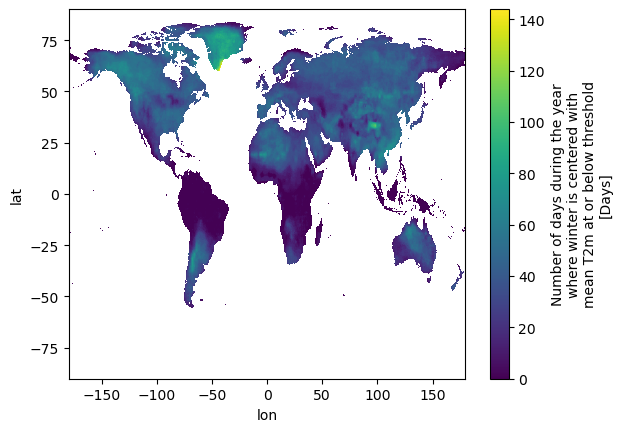

In [8]:
sum_ds.WinterlikeDays.plot()